 TRAFFICIQ: TRAFFIC DEMAND PREDICTION USING MACHINE LEARNING

Dataset loaded successfully!
Dataset path: C:\Users\ACER\OneDrive\Desktop\a\traffic_dataset.csv
Dataset shape: (6000, 10)


,road,vehicle_count,traffic_density,queue_length,avg_speed,hour_of_day,day_of_week,is_weekend,prev_waiting_time,traffic_demand
0,South,16,33.65,51.98,37.09,6,6,1,17.08,512.84
1,South,22,39.66,118.35,36.27,19,6,1,38.36,648.40
2,East,22,39.94,91.46,40.73,14,3,0,29.82,637.24
3,North,21,37.23,38.61,37.95,10,2,0,16.68,546.76
4,South,49,83.77,233.22,23.53,7,1,0,75.50,1438.97



Dataset columns:
['road', 'vehicle_count', 'traffic_density', 'queue_length', 'avg_speed', 'hour_of_day', 'day_of_week', 'is_weekend', 'prev_waiting_time', 'traffic_demand']

Missing values:
road                 0
vehicle_count        0
traffic_density      0
queue_length         0
avg_speed            0
hour_of_day          0
day_of_week          0
is_weekend           0
prev_waiting_time    0
traffic_demand       0
dtype: int64

Usable records: 6000


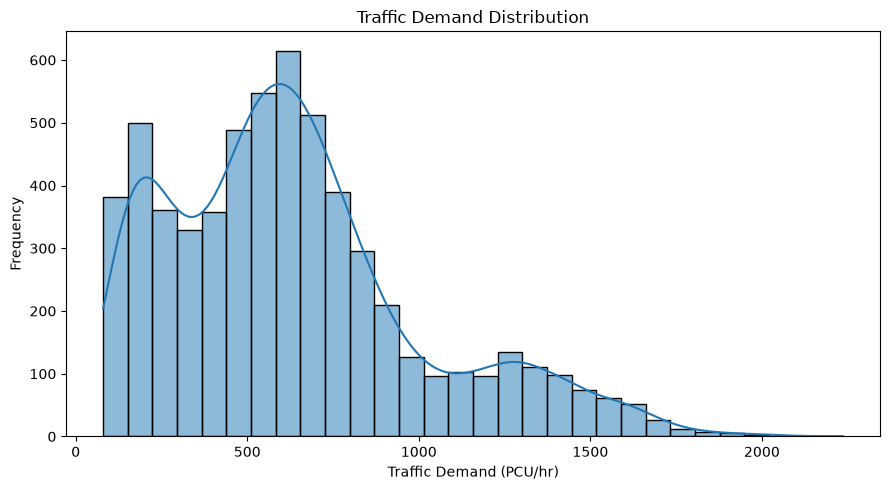

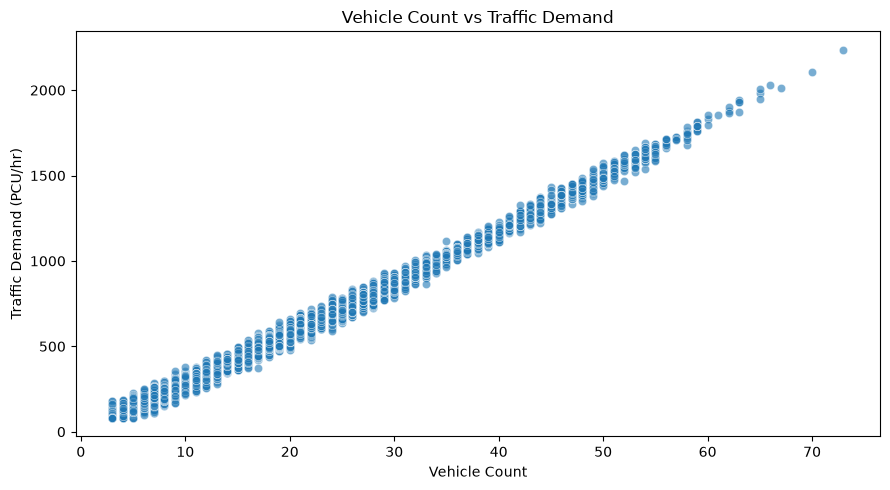

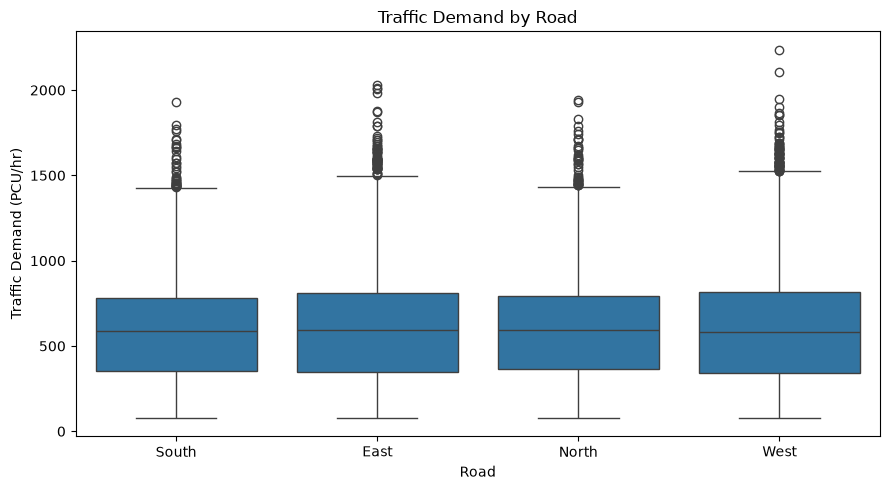


Training records: 4800
Testing records: 1200

Training Random Forest model...
Model trained successfully!

MODEL EVALUATION RESULTS
Mean Absolute Error : 21.72 PCU/hr
Mean Squared Error  : 732.44
Root Mean Squared Error: 27.06 PCU/hr
R2 Score            : 0.9945

Actual vs Predicted Traffic Demand:


,Actual Traffic Demand,Predicted Traffic Demand
0,496.36,487.566777
1,381.29,314.305832
2,460.55,472.842723
3,1044.11,1025.901489
4,420.22,417.623277
5,1042.72,1028.170942
6,761.23,763.375577
7,139.13,133.033959
8,147.73,171.316881
9,527.95,543.739221


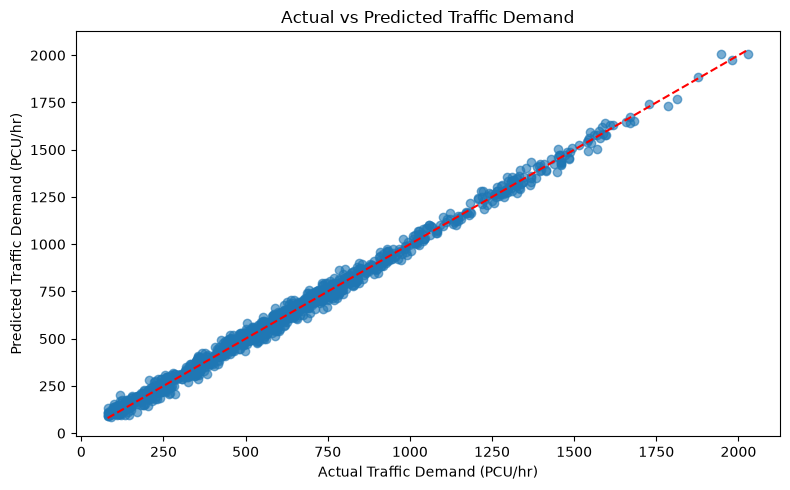


Feature Importance:


,Feature,Importance
4,vehicle_count,0.991668
5,traffic_density,0.002698
6,queue_length,0.002058
7,avg_speed,0.001853
11,prev_waiting_time,0.000783
8,hour_of_day,0.000350
9,day_of_week,0.000280
3,road_West,0.000073
2,road_South,0.000071
0,road_East,0.000069


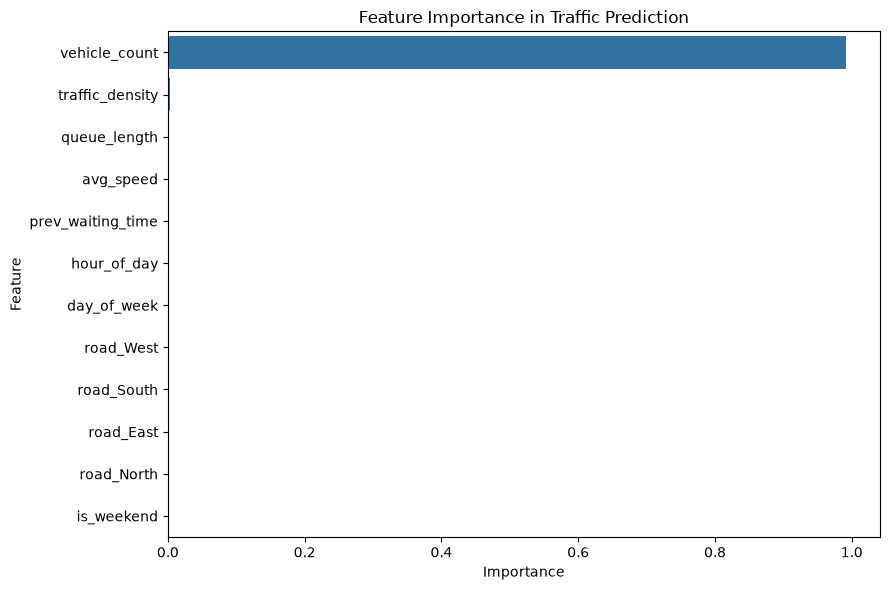


SAMPLE TRAFFIC PREDICTION


,road,vehicle_count,traffic_density,queue_length,avg_speed,hour_of_day,day_of_week,is_weekend,prev_waiting_time
1782,North,17,30.43,62.35,40.02,13,1,0,24.33


Predicted Traffic Demand: 487.57 PCU/hr
Actual Traffic Demand: 496.36 PCU/hr

PROJECT COMPLETED SUCCESSFULLY!
Trained model: C:\Users\ACER\OneDrive\Desktop\a\models\traffic_rf_model.joblib
Model metadata: C:\Users\ACER\OneDrive\Desktop\a\models\model_metadata.json
Final R2 Score: 0.9945
Saved model prediction: 487.57 PCU/hr
All steps completed!


In [1]:

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 60)
print(" TRAFFICIQ: TRAFFIC DEMAND PREDICTION USING MACHINE LEARNING")
print("=" * 60)

# Step 1: Load dataset
possible_paths = [
    r"C:\Users\ACER\Desktop\a\traffic_dataset.csv",
    r"C:\Users\ACER\OneDrive\Desktop\a\traffic_dataset.csv",
    os.path.join(os.path.expanduser("~"), "Desktop", "a", "traffic_dataset.csv"),
    os.path.join(os.path.expanduser("~"), "OneDrive", "Desktop", "a", "traffic_dataset.csv")
]

file_path = next((p for p in possible_paths if os.path.exists(p)), None)

if file_path is None:
    raise FileNotFoundError(
        "Dataset not found. Check that traffic_dataset.csv is inside "
        "Desktop folder 'a', or update file_path to its actual location."
    )

df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("Dataset path:", file_path)
print("Dataset shape:", df.shape)
display(df.head())

# Step 2: Check dataset
print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

# Step 3: Define features and target
features = [
    "road",
    "vehicle_count",
    "traffic_density",
    "queue_length",
    "avg_speed",
    "hour_of_day",
    "day_of_week",
    "is_weekend",
    "prev_waiting_time"
]

target = "traffic_demand"

missing_columns = [c for c in features + [target] if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df = df.dropna(subset=features + [target]).copy()

if df.empty:
    raise ValueError("No usable records remain after removing missing values.")

X = df[features]
y = df[target]

print("\nUsable records:", len(df))

# Step 4: Visualize traffic demand
plt.figure(figsize=(9, 5))
sns.histplot(df[target], bins=30, kde=True)
plt.title("Traffic Demand Distribution")
plt.xlabel("Traffic Demand (PCU/hr)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Step 5: Vehicle count vs traffic demand
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="vehicle_count", y=target, alpha=0.6)
plt.title("Vehicle Count vs Traffic Demand")
plt.xlabel("Vehicle Count")
plt.ylabel("Traffic Demand (PCU/hr)")
plt.tight_layout()
plt.show()

# Step 6: Traffic demand by road
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="road", y=target)
plt.title("Traffic Demand by Road")
plt.xlabel("Road")
plt.ylabel("Traffic Demand (PCU/hr)")
plt.tight_layout()
plt.show()

# Step 7: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# Step 8: Preprocess data
categorical_features = ["road"]
numerical_features = [c for c in features if c != "road"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", StandardScaler(), numerical_features)
    ]
)

# Step 9: Create Random Forest model
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=120,
            max_depth=14,
            min_samples_split=4,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Step 10: Train model
print("\nTraining Random Forest model...")
model.fit(X_train, y_train)
print("Model trained successfully!")

# Step 11: Evaluate model
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n" + "=" * 50)
print("MODEL EVALUATION RESULTS")
print("=" * 50)
print(f"Mean Absolute Error : {mae:.2f} PCU/hr")
print(f"Mean Squared Error  : {mse:.2f}")
print(f"Root Mean Squared Error: {rmse:.2f} PCU/hr")
print(f"R2 Score            : {r2:.4f}")
print("=" * 50)

# Step 12: Compare actual and predicted values
results = pd.DataFrame({
    "Actual Traffic Demand": y_test.to_numpy(),
    "Predicted Traffic Demand": y_pred
})

print("\nActual vs Predicted Traffic Demand:")
display(results.head(15))

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual Traffic Demand (PCU/hr)")
plt.ylabel("Predicted Traffic Demand (PCU/hr)")
plt.title("Actual vs Predicted Traffic Demand")
plt.tight_layout()
plt.show()

# Step 13: Feature importance
encoder = model.named_steps["preprocessor"].named_transformers_["cat"]
encoded_features = encoder.get_feature_names_out(["road"]).tolist()
all_features = encoded_features + numerical_features

importance_df = pd.DataFrame({
    "Feature": all_features,
    "Importance": model.named_steps["regressor"].feature_importances_
}).sort_values("Importance", ascending=False)

print("\nFeature Importance:")
display(importance_df)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Feature Importance in Traffic Prediction")
plt.tight_layout()
plt.show()

# Step 14: Predict traffic demand for a test record
sample = X_test.iloc[[0]].copy()
prediction = model.predict(sample)[0]

print("\nSAMPLE TRAFFIC PREDICTION")
display(sample)
print(f"Predicted Traffic Demand: {prediction:.2f} PCU/hr")
print(f"Actual Traffic Demand: {y_test.iloc[0]:.2f} PCU/hr")

# Step 15: Save trained model and metadata
output_dir = os.path.join(os.path.dirname(file_path), "models")
os.makedirs(output_dir, exist_ok=True)

model_file = os.path.join(output_dir, "traffic_rf_model.joblib")
metadata_file = os.path.join(output_dir, "model_metadata.json")

joblib.dump(model, model_file)

metadata = {
    "project": "TrafficIQ",
    "model_type": "RandomForestRegressor",
    "n_estimators": 120,
    "max_depth": 14,
    "random_seed": 42,
    "training_samples": int(len(X_train)),
    "testing_samples": int(len(X_test)),
    "mae": float(mae),
    "mse": float(mse),
    "rmse": float(rmse),
    "r2_score": float(r2),
    "target_variable": target,
    "features": features,
    "feature_importances": {
        row["Feature"]: float(row["Importance"])
        for _, row in importance_df.iterrows()
    },
    "training_timestamp": datetime.now().isoformat()
}

with open(metadata_file, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("\n" + "=" * 60)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("=" * 60)
print("Trained model:", model_file)
print("Model metadata:", metadata_file)
print(f"Final R2 Score: {r2:.4f}")

# Step 16: Verify saved model
loaded_model = joblib.load(model_file)
loaded_prediction = loaded_model.predict(sample)[0]

print(f"Saved model prediction: {loaded_prediction:.2f} PCU/hr")
print("All steps completed!")

